In [45]:
print("bắt đầu dự án dự dự báo doanh thu")

bắt đầu dự án dự dự báo doanh thu


In [46]:
import pandas as pd

df = pd.read_csv("train.csv")
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           17000 non-null  float64
 1   latitude            17000 non-null  float64
 2   housing_median_age  17000 non-null  float64
 3   total_rooms         17000 non-null  float64
 4   total_bedrooms      17000 non-null  float64
 5   population          17000 non-null  float64
 6   households          17000 non-null  float64
 7   median_income       17000 non-null  float64
 8   median_house_value  17000 non-null  float64
dtypes: float64(9)
memory usage: 1.2 MB


In [48]:
import pandas as pd

df = pd.read_csv("/train.csv")
print(df.shape)
print(df.columns.tolist())

(9800, 18)
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']


In [49]:
df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True)

monthly = df.set_index("Order Date")["Sales"].resample("MS").sum()

print(len(monthly))
monthly.head(12)

48


,Sales
Order Date,
2015-01-01,14205.7070
2015-02-01,4519.8920
2015-03-01,55205.7970
2015-04-01,27906.8550
2015-05-01,23644.3030
2015-06-01,34322.9356
2015-07-01,33781.5430
2015-08-01,27117.5365
2015-09-01,81623.5268


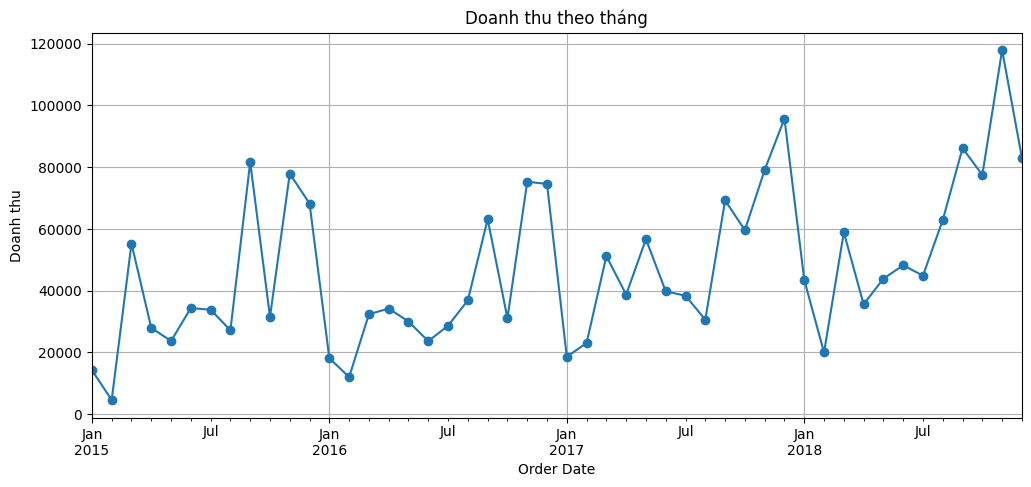

In [50]:
import matplotlib.pyplot as plt

monthly.plot(figsize=(12, 5), marker="o")
plt.title("Doanh thu theo tháng")
plt.ylabel("Doanh thu")
plt.grid(True)
plt.show()

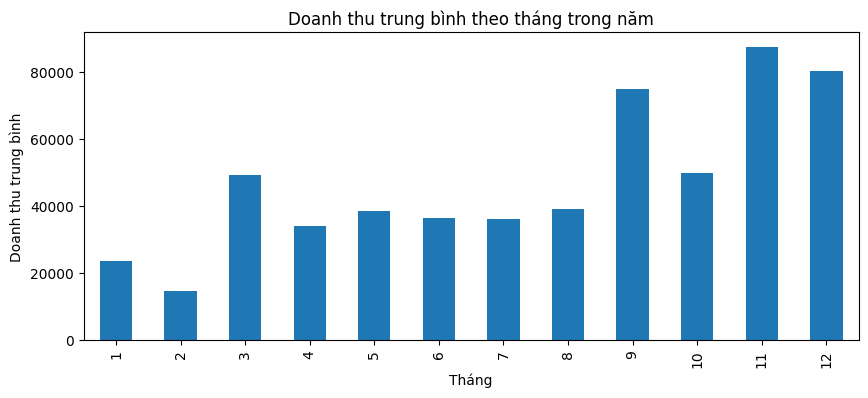

In [51]:
monthly.groupby(monthly.index.month).mean().plot(kind="bar", figsize=(10, 4))
plt.title("Doanh thu trung bình theo tháng trong năm")
plt.xlabel("Tháng")
plt.ylabel("Doanh thu trung bình")
plt.show()

In [52]:
train = monthly[:-12]
test = monthly[-12:]

baseline = pd.Series(train[-12:].values, index=test.index)

mae_base = (test - baseline).abs().mean()
mape_base = ((test - baseline).abs() / test).mean() * 100

print("Baseline MAE:", round(mae_base))
print("Baseline MAPE:", round(mape_base, 1), "%")

Baseline MAE: 15444
Baseline MAPE: 24.9 %


Holt-Winters MAE: 12519
Holt-Winters MAPE: 21.1 %


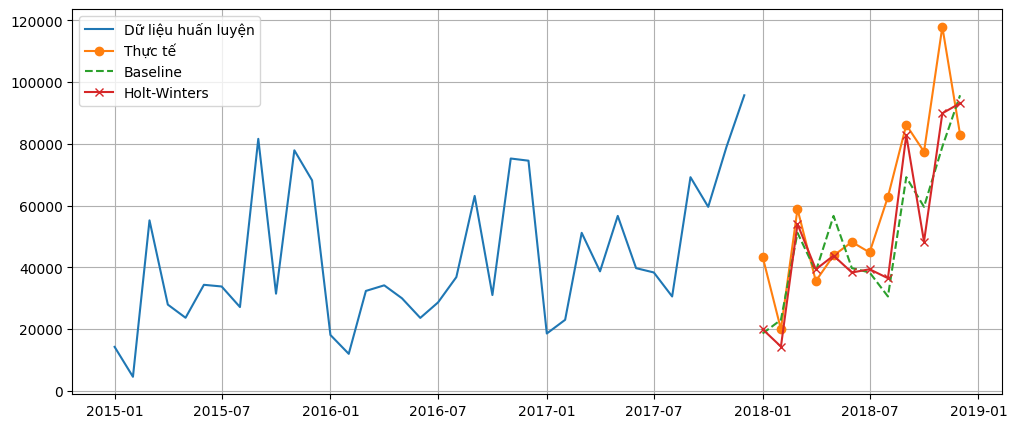

In [53]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import matplotlib.pyplot as plt

model = ExponentialSmoothing(
    train, trend="add", seasonal="mul", seasonal_periods=12
).fit()
forecast = model.forecast(12)

mae_hw = (test - forecast).abs().mean()
mape_hw = ((test - forecast).abs() / test).mean() * 100

print("Holt-Winters MAE:", round(mae_hw))
print("Holt-Winters MAPE:", round(mape_hw, 1), "%")

plt.figure(figsize=(12, 5))
plt.plot(train, label="Dữ liệu huấn luyện")
plt.plot(test, label="Thực tế", marker="o")
plt.plot(baseline, label="Baseline", linestyle="--")
plt.plot(forecast, label="Holt-Winters", marker="x")
plt.legend()
plt.grid(True)
plt.show()

In [54]:
configs = {
    "Xu hướng + mùa nhân": dict(trend="add", seasonal="mul"),
    "Xu hướng + mùa cộng": dict(trend="add", seasonal="add"),
    "Không xu hướng + mùa nhân": dict(trend=None, seasonal="mul"),
    "Không xu hướng + mùa cộng": dict(trend=None, seasonal="add"),
}

for name, cfg in configs.items():
    m = ExponentialSmoothing(train, seasonal_periods=12, **cfg).fit()
    f = m.forecast(12)
    mae = (test - f).abs().mean()
    mape = ((test - f).abs() / test).mean() * 100
    print(name, "| MAE:", round(mae), "| MAPE:", round(mape, 1), "%")

Xu hướng + mùa nhân | MAE: 12519 | MAPE: 21.1 %
Xu hướng + mùa cộng | MAE: 10545 | MAPE: 19.8 %
Không xu hướng + mùa nhân | MAE: 13700 | MAPE: 23.5 %
Không xu hướng + mùa cộng | MAE: 11459 | MAPE: 18.2 %


2019-01-01     49393.0
2019-02-01     41600.0
2019-03-01     71943.0
2019-04-01     60876.0
2019-05-01     68134.0
2019-06-01     62708.0
2019-07-01     66241.0
2019-08-01     65234.0
2019-09-01    105703.0
2019-10-01     76598.0
2019-11-01    114262.0
2019-12-01    116353.0
Freq: MS, dtype: float64
Tổng 2018: 722052
Tổng dự báo 2019: 899044


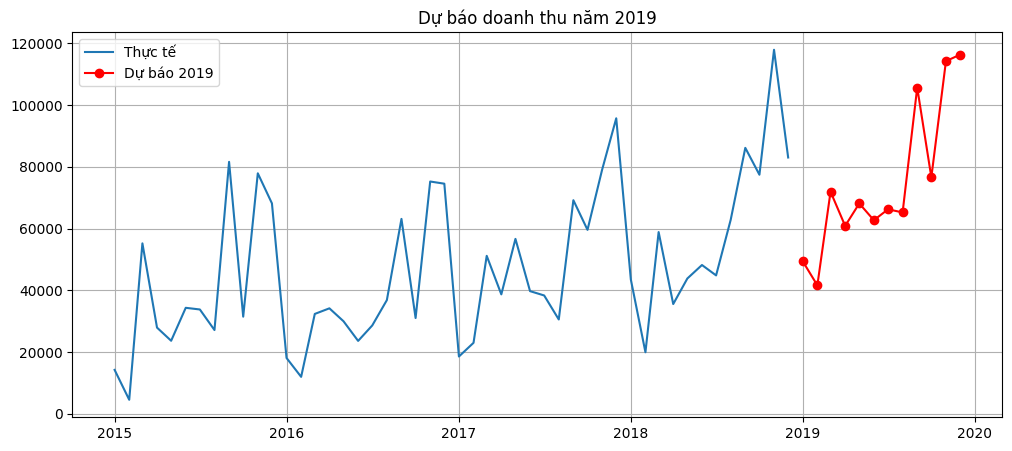

In [55]:
final_model = ExponentialSmoothing(
    monthly, trend="add", seasonal="add", seasonal_periods=12
).fit()
forecast_2019 = final_model.forecast(12)

print(forecast_2019.round())
print("Tổng 2018:", round(monthly[-12:].sum()))
print("Tổng dự báo 2019:", round(forecast_2019.sum()))

plt.figure(figsize=(12, 5))
plt.plot(monthly, label="Thực tế")
plt.plot(forecast_2019, label="Dự báo 2019", marker="o", color="red")
plt.title("Dự báo doanh thu năm 2019")
plt.legend()
plt.grid(True)
plt.show()

In [56]:
yearly = monthly.resample("YS").sum()
print(yearly.round())
print((yearly.pct_change() * 100).round(1))

print("3 tháng cao nhất 2019:")
print(forecast_2019.nlargest(3).round())
print("3 tháng thấp nhất 2019:")
print(forecast_2019.nsmallest(3).round())

Order Date
2015-01-01    479856.0
2016-01-01    459436.0
2017-01-01    600193.0
2018-01-01    722052.0
Freq: YS-JAN, Name: Sales, dtype: float64
Order Date
2015-01-01     NaN
2016-01-01    -4.3
2017-01-01    30.6
2018-01-01    20.3
Freq: YS-JAN, Name: Sales, dtype: float64
3 tháng cao nhất 2019:
2019-12-01    116353.0
2019-11-01    114262.0
2019-09-01    105703.0
dtype: float64
3 tháng thấp nhất 2019:
2019-02-01    41600.0
2019-01-01    49393.0
2019-04-01    60876.0
dtype: float64
